<a href="https://colab.research.google.com/github/felpontes98/jornada-engenharia-software/blob/main/machine-learning/classificacao-svm-peixes/svm_fishmorph_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TEORIA E PRÁTICA DE INTELIGÊNCIA ARTIFICIAL



# Projeto: Classificação com SVM (Support Vector Machines)

Neste notebook, vou construir um modelo de classificação do zero usando a biblioteca `scikit-learn`. Como a ideia é aplicar as boas práticas de Engenharia de Software, o foco aqui não é só fazer o código rodar, mas deixar o processo organizado, fácil de entender e livre de vieses.

Antes de qualquer coisa, precisamos trazer as ferramentas de trabalho. Em vez de importar tudo de uma vez de forma bagunçada, separei as bibliotecas por categoria (dados, gráficos e modelagem).

*Detalhe importante:* Já estou importando ferramentas de automação como o `GridSearchCV`. A ideia é construir um fluxo inteligente, testando as melhores configurações do modelo sem precisar ficar mudando os parâmetros na mão.

In [ ]:
# 1. Lidando com arquivos e dados
import os
import kagglehub
import pandas as pd
import numpy as np

# 2. Gráficos e visualizações
import matplotlib.pyplot as plt
import seaborn as sns

# 3. Machine Learning (Scikit-Learn)
# Preparação dos dados
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder

# Estruturação e busca de parâmetros
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# O modelo em si
from sklearn.svm import SVC

# Ferramentas para métricas
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## 1. Coleta dos Dados

Em vez de baixar o dataset manualmente e fazer o upload para o Colab toda vez que a máquina virtual for reiniciada, vou usar a biblioteca `kagglehub` para automatizar isso.

Essa é uma boa prática de Engenharia de Software porque garante a reprodutibilidade do projeto. O dataset escolhido para este projeto é o **Fishmorph** (dados morfológicos de peixes).

In [ ]:
# 1. Baixando os dados diretamente do repositório do Kaggle
path = kagglehub.dataset_download('menegidio/fishmorph-dataset')

print("Diretório do dataset:")
print(path)

print("\nArquivos encontrados na pasta:")
print(os.listdir(path))

Using Colab cache for faster access to the 'fishmorph-dataset' dataset.
Diretório do dataset:
/kaggle/input/fishmorph-dataset

Arquivos encontrados na pasta:
['FISHMORPH_Order_Dataset.csv', 'FISHMORPH_Family_Dataset.csv']


## 2. Leitura e Exploração Inicial dos Dados

Com os dados baixados, o próximo passo é localizar o arquivo exato dentro do diretório e carregá-lo em um DataFrame do Pandas. Vamos dar a primeira olhada na estrutura e verificar se existem valores nulos.

In [ ]:
# 1. Mapeando o arquivo exato e lendo o CSV
path_completo = os.path.join(path, 'FISHMORPH_Family_Dataset.csv')
df_fish = pd.read_csv(path_completo)

# 2. Visualizando as primeiras linhas
display(df_fish.head())

# 3. Entendendo a estrutura e os dados faltantes
print("\nInformações do Dataset:")
df_fish.info()

print("\nValores Nulos por Coluna:")
print(df_fish.isnull().sum())

,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Family
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cyprinidae
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Cichlidae
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cyprinidae
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cyprinidae
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cyprinidae



Informações do Dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8342 entries, 0 to 8341
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   MBl     8342 non-null   float64
 1   BEl     8342 non-null   float64
 2   VEp     8342 non-null   float64
 3   REs     8342 non-null   float64
 4   OGp     8342 non-null   float64
 5   RMl     8342 non-null   float64
 6   BLs     8342 non-null   float64
 7   PFv     8342 non-null   float64
 8   PFs     8342 non-null   float64
 9   CPt     8342 non-null   float64
 10  Family  8342 non-null   object 
dtypes: float64(10), object(1)
memory usage: 717.0+ KB

Valores Nulos por Coluna:
MBl       0
BEl       0
VEp       0
REs       0
OGp       0
RMl       0
BLs       0
PFv       0
PFs       0
CPt       0
Family    0
dtype: int64


## 3. Limpeza e Tratamento de Dados (Ausentes e Duplicados)

A estratégia estruturada para limpar a sujeira do dataset será:
1. Remover colunas específicas que não vão agregar ao modelo (`CPt` e `PFs`).
2. Identificar e remover linhas **duplicadas** para evitar que o modelo aprenda com dados repetidos (evitando viés).
3. Remover linhas que não possuem a classificação alvo preenchida (se não sabemos a família do peixe, a linha não serve para treino).
4. Preencher os nulos restantes nas colunas numéricas usando a média de cada característica.

In [ ]:
# 1. Removendo colunas indesejadas
excluir_colunas_df_fish = ['CPt', 'PFs']
df_fish = df_fish.drop(columns=excluir_colunas_df_fish)

# 2. Verificando e removendo dados duplicados
duplicados = df_fish.duplicated().sum()
print(f"Linhas duplicadas encontradas e removidas: {duplicados}")
df_fish = df_fish.drop_duplicates()

# 3. Removendo nulos da coluna alvo ('Family')
df_fish = df_fish.dropna(subset=['Family'])

# 4. Preenchendo nulos numéricos com a média
media = df_fish.mean(numeric_only=True)
df_fish = df_fish.fillna(media)

# 5. Garantia extra para remover qualquer nulo residual
df_fish = df_fish.dropna()

Linhas duplicadas encontradas e removidas: 1


## 4. Filtragem de Classes, Variável Alvo e Separação (Treino/Teste)

Durante a exploração, notamos um alto desbalanceamento. Como vamos utilizar Validação Cruzada com 5 divisões (`cv=5`), configuramos um filtro para manter apenas as famílias com **7 ou mais representantes**. Isso garante que o particionamento de treino (80%) receba pelo menos 5 amostras, evitando erros na hora do `GridSearchCV`.

Após a filtragem, convertemos o texto para números com `LabelEncoder` e dividimos os dados usando `stratify` para manter as proporções reais entre treino e teste.

In [ ]:
# 1. Filtrando as famílias (Mínimo de 7 amostras para não quebrar o CV=5)
print("Famílias ANTES do filtro:", df_fish['Family'].nunique())

contagem_familias = df_fish['Family'].value_counts()
familias_validas = contagem_familias[contagem_familias >= 7].index

df_fish = df_fish[df_fish['Family'].isin(familias_validas)]
print("Famílias DEPOIS do filtro:", df_fish['Family'].nunique())

# 2. Convertendo texto para números
encoder = LabelEncoder()
df_fish['Family'] = encoder.fit_transform(df_fish['Family'])

# 3. Separando X (features) e y (target)
X_fish = df_fish[['MBl', 'BEl', 'VEp', 'REs', 'OGp', 'RMl', 'BLs', 'PFv']]
y_fish = df_fish['Family']

# 4. Divisão de Treino e Teste
X_fish_train, X_fish_test, y_fish_train, y_fish_test = train_test_split(
    X_fish, y_fish, test_size=0.2, random_state=42, stratify=y_fish
)

print(f"\nTreino: {X_fish_train.shape[0]} amostras | Teste: {X_fish_test.shape[0]} amostras")

Famílias ANTES do filtro: 197
Famílias DEPOIS do filtro: 107

Treino: 6504 amostras | Teste: 1626 amostras


## 4.1. Análise Exploratória: Visualizando a Distribuição das Categorias

Para ter uma visão clara do desbalanceamento das classes, vamos plotar um gráfico.
*Decisão de visualização:* Como nosso dataset possui dezenas de famílias, exibir todas em um único gráfico deixaria a imagem ilegível. Para manter a clareza analítica, o gráfico exibirá apenas as **20 famílias mais frequentes**.

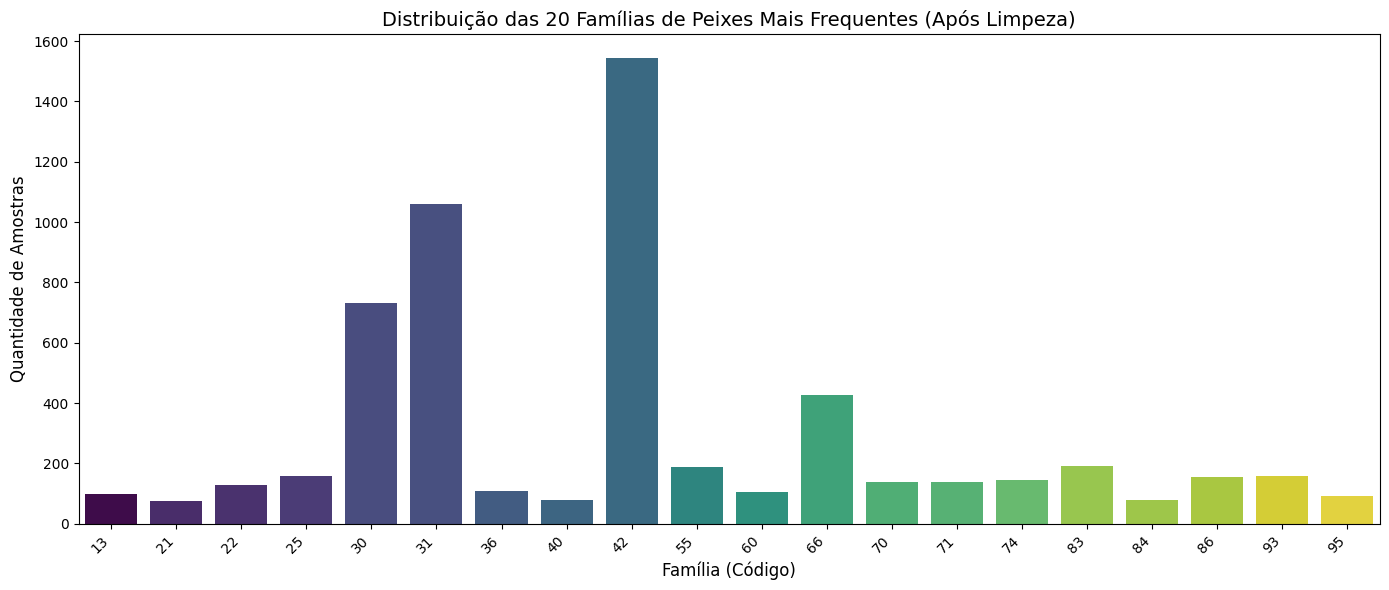

In [ ]:
# 1. Visualização da distribuição das categorias (Exigência da Prova)
plt.figure(figsize=(14, 6))

familias_frequentes = df_fish['Family'].value_counts().head(20)

# 2. Plotagem do gráfico com 'hue' para evitar advertências da biblioteca
sns.barplot(
    x=familias_frequentes.index,
    y=familias_frequentes.values,
    hue=familias_frequentes.index,
    palette='viridis',
    legend=False
)

plt.title('Distribuição das 20 Famílias de Peixes Mais Frequentes (Após Limpeza)', fontsize=14)
plt.xlabel('Família (Código)', fontsize=12)
plt.ylabel('Quantidade de Amostras', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## 5. Padronização e Otimização do Modelo

Nesta etapa, focamos no pré-processamento e no treinamento:
1. **Padronização:** Usamos o `StandardScaler` (`fit_transform` no treino e apenas `transform` no teste) para evitar *Data Leakage*.
2. **Busca de Hiperparâmetros:** Utilizamos o `GridSearchCV` testando rigorosamente 4 diferentes Kernels, 4 valores de `C` e 4 de `gamma` simultaneamente, usando todos os núcleos do servidor (`n_jobs=-1`).

In [ ]:
# 1. Padronização (Evitando Data Leakage)
scaler_fish = StandardScaler()
X_fish_train = scaler_fish.fit_transform(X_fish_train)
X_fish_test = scaler_fish.transform(X_fish_test)

# 2. Treinamento e Otimização (Exigência da Prova: 64 Combinações)
parametros = {
    'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
    'C': [0.1, 1, 10, 100],
    'gamma': [0.001, 0.01, 0.1, 1]
}

svm_fish = SVC()
grid_fish = GridSearchCV(svm_fish, parametros, cv=5, n_jobs=-1)

print("Iniciando o treinamento. Como o kernel 'poly' foi exigido, aguarde alguns minutos...")
grid_fish.fit(X_fish_train, y_fish_train)

print("\nTreinamento concluído com sucesso!")

Iniciando o treinamento. Como o kernel 'poly' foi exigido, aguarde alguns minutos...

Treinamento concluído com sucesso!


## 6. Avaliação e Métricas Finais

Com o modelo treinado, extraímos a melhor configuração encontrada pela máquina e a testamos contra os nossos 20% de dados inéditos. O objetivo aqui é validar a **Acurácia**, gerar o **Relatório de Classificação** e visualizar onde o modelo se confunde usando a **Matriz de Confusão**.

Resultados do Treinamento Interno:
Melhores hiperparâmetros: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'}
Melhor Score de Validação (GridSearch): 0.6279

Resultados no Conjunto de Teste (Mundo Real):
Acurácia Geral: 0.6421 (ou 64.21%)

Relatório de Classificação:
              precision    recall  f1-score   support

           0       0.17      0.25      0.20         4
           1       0.60      1.00      0.75         3
           2       1.00      0.50      0.67         2
           3       1.00      1.00      1.00         4
           4       1.00      1.00      1.00         1
           5       0.33      0.33      0.33         3
           6       0.50      0.07      0.12        15
           7       1.00      0.80      0.89         5
           8       0.00      0.00      0.00         3
           9       0.71      0.62      0.67         8
          10       1.00      0.25      0.40         4
          11       1.00      0.50      0.67         2
          12       1.00      1.00    

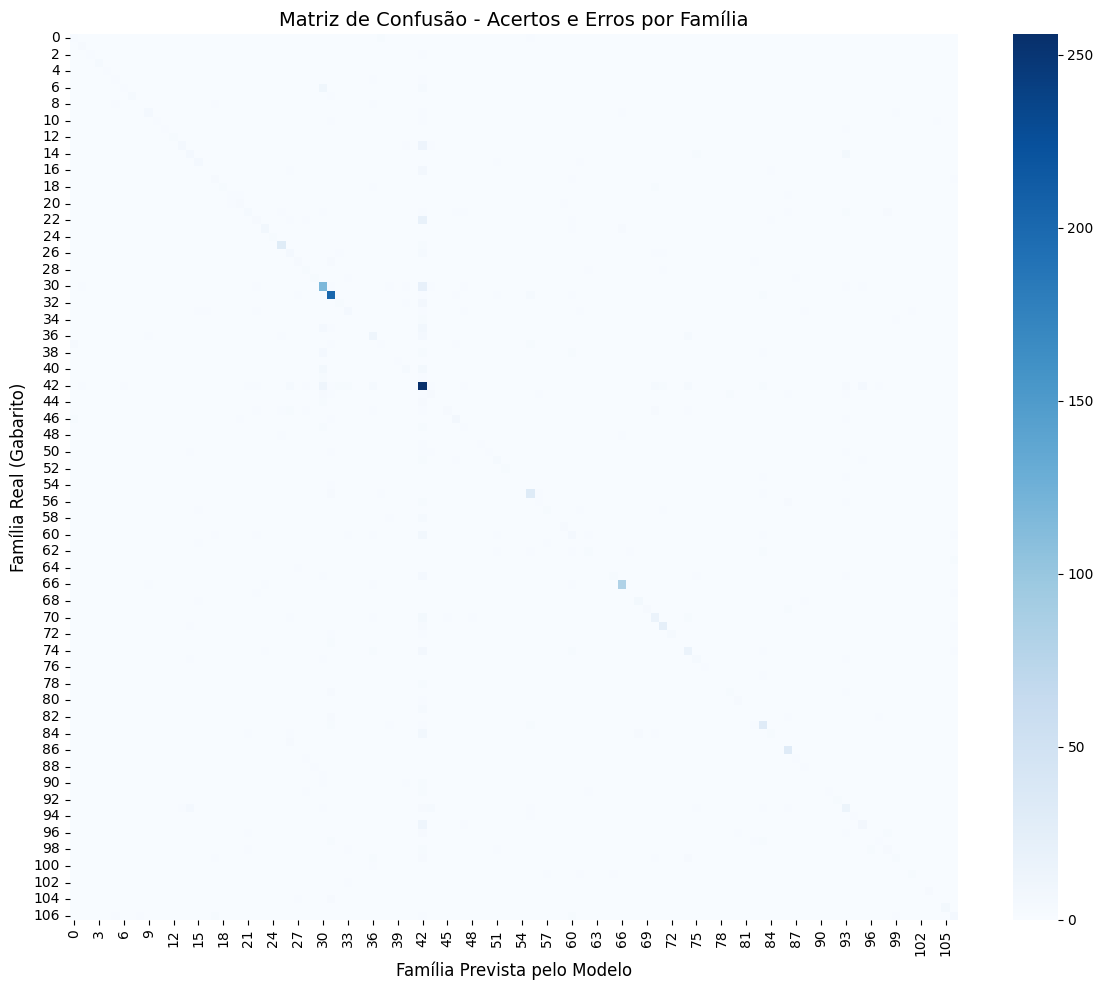

In [ ]:
# 1. Extração do melhor modelo
melhor_modelo_svm = grid_fish.best_estimator_

print("Resultados do Treinamento Interno:")
print(f"Melhores hiperparâmetros: {grid_fish.best_params_}")
print(f"Melhor Score de Validação (GridSearch): {grid_fish.best_score_:.4f}\n")

# 2. Avaliação com dados inéditos
y_pred_fish = melhor_modelo_svm.predict(X_fish_test)
acuracia = accuracy_score(y_fish_test, y_pred_fish)

print("Resultados no Conjunto de Teste (Mundo Real):")
print(f"Acurácia Geral: {acuracia:.4f} (ou {acuracia * 100:.2f}%)\n")

print("Relatório de Classificação:")
print(classification_report(y_fish_test, y_pred_fish, zero_division=0))

# 3. Visualização: Matriz de Confusão
matriz = confusion_matrix(y_fish_test, y_pred_fish)

plt.figure(figsize=(12, 10))
sns.heatmap(matriz, annot=False, cmap='Blues', fmt='g')
plt.title('Matriz de Confusão - Acertos e Erros por Família', fontsize=14)
plt.xlabel('Família Prevista pelo Modelo', fontsize=12)
plt.ylabel('Família Real (Gabarito)', fontsize=12)
plt.tight_layout()
plt.show()